# 04 — Đánh giá và biểu đồ

**Notebook gốc:** bước 5–6: đối chiếu Isolation Forest, Autoencoder và Ensemble theo ngày; đọc **kết quả đã lưu** từ notebook 03, không tự huấn luyện lại. Cần chạy `03_model_training.ipynb` hoặc `python run_pipeline.py` trước.

In [1]:
from pathlib import Path
import sys
PROJECT_ROOT = Path.cwd().resolve()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "src").exists():
    raise RuntimeError("Mở thư mục project trên VS Code, hoặc chạy notebook trong notebooks/.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from src import config as cfg
print("Project:", PROJECT_ROOT)
print("Dataset:", cfg.DATA_DIR)


Project: D:\network-anomaly-hybrid-vscode\network-anomaly-hybrid-vscode
Dataset: D:\network-anomaly-hybrid-vscode\network-anomaly-hybrid-vscode\data\raw


In [2]:
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Image
metrics_dir = cfg.OUT_DIR / 'metrics'
p = metrics_dir / 'metrics_by_day.csv'
if not p.exists():
    raise FileNotFoundError('Chưa có metrics_by_day.csv: chạy notebook 03 hoặc python run_pipeline.py trước.')
mdf = pd.read_csv(p)
display(mdf.round(4))


,model,day,n,attack_rate,recall,fpr,precision,f1,roc_auc,pr_auc
0,Isolation Forest,2018-02-20,239192,0.6032,0.0000,0.0307,0.0021,0.0001,0.7488,0.6992
1,Isolation Forest,2018-02-21,139945,0.3577,0.0001,0.0052,0.0128,0.0002,0.0587,0.2103
2,Isolation Forest,2018-02-22,208226,0.0004,0.1071,0.0263,0.0016,0.0032,0.7596,0.0012
3,Isolation Forest,2018-02-23,207464,0.0007,0.3475,0.0265,0.0088,0.0172,0.8293,0.0070
4,Isolation Forest,2018-02-28,114426,0.1238,0.0523,0.0559,0.1167,0.0722,0.5070,0.1244
5,Isolation Forest,2018-03-01,62659,0.2476,0.0743,0.0527,0.3171,0.1204,0.5155,0.2681
6,Isolation Forest,2018-03-02,192876,0.1870,0.0067,0.0340,0.0436,0.0117,0.8795,0.4392
7,Isolation Forest,ALL,1164788,0.2235,0.0085,0.0307,0.0736,0.0152,0.6697,0.2803
8,Autoencoder,2018-02-20,239192,0.6032,0.0013,0.0000,0.9948,0.0027,0.9633,0.9452
9,Autoencoder,2018-02-21,139945,0.3577,0.0085,0.0000,1.0000,0.0168,0.0088,0.2136


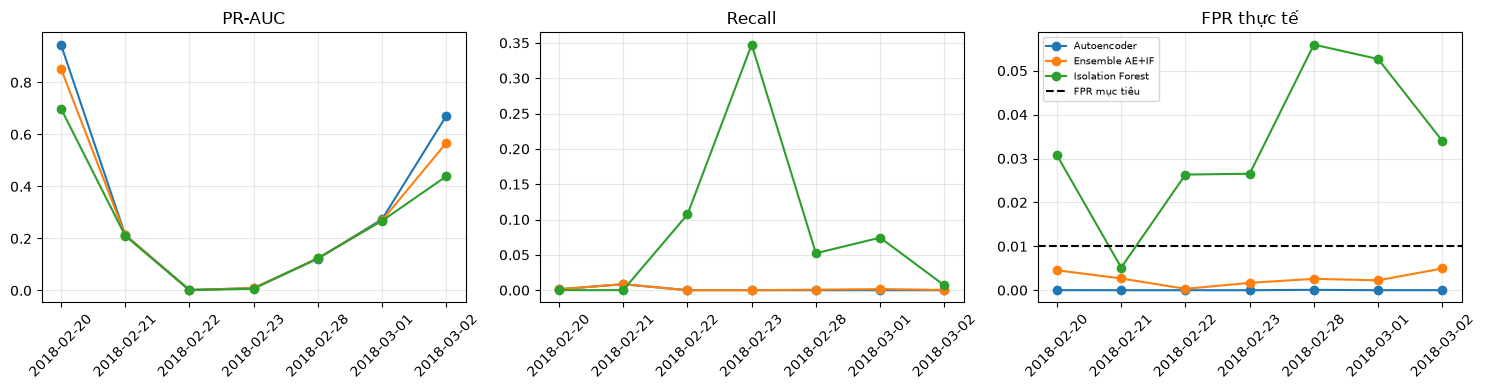

In [3]:
daily = mdf[mdf['day'] != 'ALL'].copy()
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for name, group in daily.groupby('model'):
    for j, metric in enumerate(['pr_auc','recall','fpr']):
        ax[j].plot(group['day'], group[metric], marker='o', label=name)
for j, title in enumerate(['PR-AUC','Recall','FPR thực tế']):
    ax[j].set_title(title); ax[j].tick_params(axis='x',rotation=45); ax[j].grid(alpha=.3)
ax[2].axhline(cfg.FPR_TARGET, color='black', ls='--', label='FPR mục tiêu')
ax[2].legend(fontsize=7)
plt.tight_layout(); plt.show()


In [4]:
p = metrics_dir / 'recall_by_attack.csv'
if p.exists():
    display(pd.read_csv(p).sort_values(['day','label_raw']).round(4))
p = cfg.OUT_DIR / 'predictions' / 'test_scored'
print('Predictions parquet:', p, 'exists=', p.exists())


,day,label_raw,n,recall
5,2018-02-20,DDoS attacks-LOIC-HTTP,144279,0.0013
7,2018-02-21,DDOS attack-HOIC,49630,0.0000
6,2018-02-21,DDOS attack-LOIC-UDP,429,0.9907
4,2018-02-22,Brute Force -Web,58,0.0000
3,2018-02-22,Brute Force -XSS,16,0.0000
2,2018-02-22,SQL Injection,10,0.0000
9,2018-02-23,Brute Force -Web,88,0.0000
10,2018-02-23,Brute Force -XSS,38,0.0000
8,2018-02-23,SQL Injection,15,0.0000
0,2018-02-28,Infilteration,14171,0.0007


Predictions parquet: D:\network-anomaly-hybrid-vscode\network-anomaly-hybrid-vscode\outputs\predictions\test_scored exists= True


**Diễn giải:** FPR hiệu chuẩn 1% là *mục tiêu trên benign validation*, không bảo đảm FPR các ngày tương lai 1%. Quan sát ngày nào mô hình vượt ngưỡng và phân tích nguyên nhân.